# 02 - Segmentasi Pelanggan dengan RFM dan KMeans

Tidak semua pelanggan sama berharganya. Notebook ini mengelompokkan 5.852 pelanggan terdaftar supaya tim pemasaran bisa memberi perlakuan berbeda: mempertahankan pelanggan terbaik, membangunkan yang mulai pasif, dan tidak membuang anggaran pada yang sudah hilang.

**Dua pendekatan yang saling melengkapi**

| Pendekatan | Kelebihan | Kekurangan |
|---|---|---|
| **Skor RFM kuantil + aturan segmen** | Transparan, mudah dijelaskan, langsung dapat dipakai | Batas segmen ditentukan manual |
| **KMeans pada fitur RFM** | Batas kelompok ditemukan dari data; k dipilih objektif lewat silhouette | Label klaster perlu ditafsirkan setelahnya |

**Definisi**

- **Recency** : hari sejak pembelian terakhir hingga tanggal acuan (10 Des 2011, sehari setelah data berakhir).
- **Frequency**: jumlah invoice penjualan yang berbeda.
- **Monetary** : total nilai pembelian (GBP), tanpa retur.

Fungsi perhitungan ada di `src/analysis/rfm.py` dan diuji di `tests/test_rfm.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.analysis.rfm import cluster_profile, compute_rfm, fit_kmeans, prepare_cluster_features, score_rfm, select_k_by_silhouette  # noqa: E402
from src.config import ASSETS_DIR, CLEAN_PARQUET, REPORTS_DIR  # noqa: E402
from src.viz import INK_MUTED, INK_SECONDARY, OTHER_GRAY, SERIES, apply_matplotlib_style  # noqa: E402

apply_matplotlib_style()
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

sales = pd.read_parquet(CLEAN_PARQUET)
SNAPSHOT = pd.Timestamp("2011-12-10")
rfm = compute_rfm(sales, snapshot_date=SNAPSHOT)
print(f"Pelanggan terdaftar: {len(rfm):,}")
display(rfm.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T)

Pelanggan terdaftar: 5,852


,count,mean,std,min,25%,50%,75%,90%,max
customer_id,"5,852.00","15,319.71","1,714.93","12,346.00","13,837.75","15,320.50","16,802.25","17,697.90","18,287.00"
recency_days,"5,852.00",200.73,208.52,1.00,26.00,96.00,380.00,531.00,739.00
frequency,"5,852.00",6.25,12.75,1.00,1.00,3.00,7.00,13.00,373.00
monetary,"5,852.00","2,916.71","14,306.85",2.95,339.58,856.02,"2,241.03","5,392.77","580,987.04"


## 1. Distribusi Recency, Frequency, Monetary

Frequency dan Monetary sangat miring ke kanan: sebagian besar pelanggan hanya belanja 1-2 kali, sementara segelintir pembeli grosir melakukan ratusan transaksi. Ini alasan mengapa KMeans nanti dijalankan pada skala log.

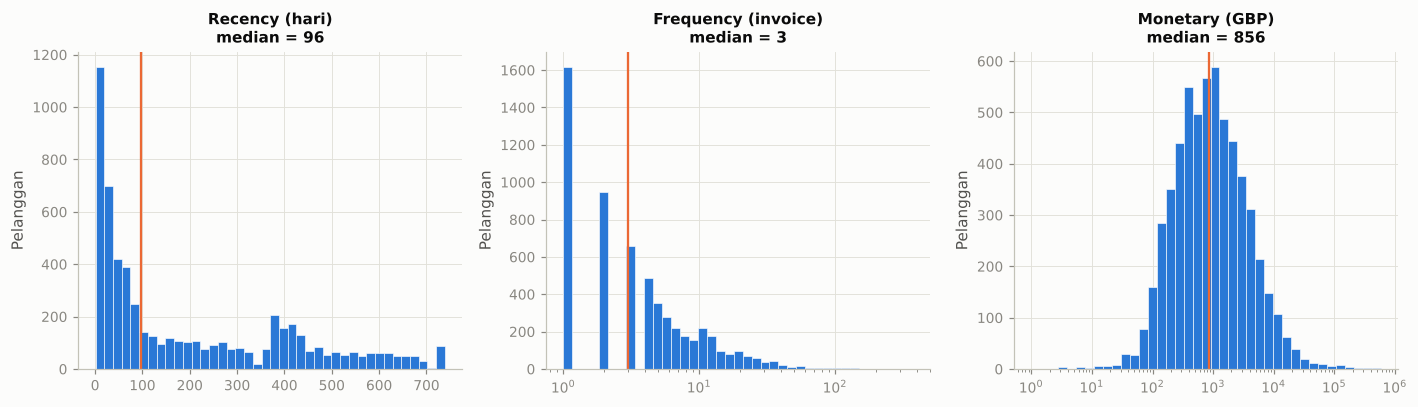

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
specs = [("recency_days", "Recency (hari)", False), ("frequency", "Frequency (invoice)", True), ("monetary", "Monetary (GBP)", True)]
for ax, (col, label, log) in zip(axes, specs):
    data = rfm[col].clip(lower=1) if log else rfm[col]
    bins = np.logspace(0, np.log10(data.max()), 40) if log else 40
    ax.hist(data, bins=bins, color=SERIES[0], edgecolor="white", linewidth=0.4)
    if log:
        ax.set_xscale("log")
    ax.axvline(rfm[col].median(), color=SERIES[1], linewidth=1.5)
    ax.set_title(f"{label}\nmedian = {rfm[col].median():,.0f}", fontsize=10)
    ax.set_ylabel("Pelanggan")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "rfm_distribusi.png")
plt.show()

## 2. Skor kuantil dan segmen berbasis aturan

Setiap dimensi diberi skor 1-5 berdasarkan kuintil (5 = terbaik: paling baru, paling sering, paling besar). Kombinasi skor dipetakan ke 8 segmen bernama dengan aturan di `segment_from_scores`. Aturan ini sama persis dengan yang dipakai di `sql/13_rfm_sql.sql` sehingga hasil SQL dan Python saling memverifikasi.

In [3]:
scored = score_rfm(rfm)
seg = scored.groupby("segment").agg(customers=("customer_id", "size"), avg_recency=("recency_days", "mean"), avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"), total_monetary=("monetary", "sum"))
seg["customers_share_pct"] = 100 * seg["customers"] / seg["customers"].sum()
seg["revenue_share_pct"] = 100 * seg["total_monetary"] / seg["total_monetary"].sum()
seg = seg.sort_values("total_monetary", ascending=False)
display(seg.round(1))

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,customers_share_pct,revenue_share_pct
segment,,,,,,,
Champions,1304,20.20,16.80,"8,975.80","11,704,410.80",22.30,68.60
Loyal Customers,832,80.10,6.90,"2,854.60","2,374,995.70",14.20,13.90
Need Attention,457,298.60,5.80,"2,514.00","1,148,908.20",7.80,6.70
Potential Loyalists,1156,68.80,2.30,624.20,"721,613.50",19.80,4.20
Hibernating,1178,395.00,1.80,567.30,"668,280.00",20.10,3.90
At Risk,68,495.10,8.10,"3,938.50","267,818.10",1.20,1.60
Lost,638,565.10,1.10,208.80,"133,245.40",10.90,0.80
New Customers,219,28.60,1.10,225.10,"49,296.20",3.70,0.30


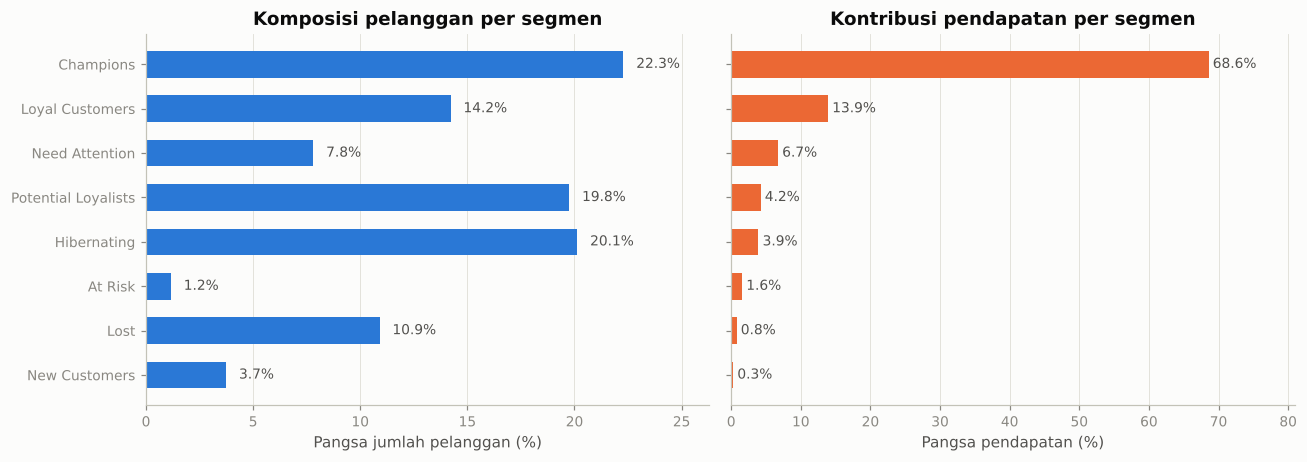

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
order = seg.index[::-1]
axes[0].barh(order, seg.loc[order, "customers_share_pct"], color=SERIES[0], height=0.6)
axes[0].set_xlabel("Pangsa jumlah pelanggan (%)")
axes[0].set_title("Komposisi pelanggan per segmen")
axes[1].barh(order, seg.loc[order, "revenue_share_pct"], color=SERIES[1], height=0.6)
axes[1].set_xlabel("Pangsa pendapatan (%)")
axes[1].set_title("Kontribusi pendapatan per segmen")
for ax, col in zip(axes, ["customers_share_pct", "revenue_share_pct"]):
    for y, name in enumerate(order):
        ax.text(seg.loc[name, col] + 0.6, y, f"{seg.loc[name, col]:.1f}%", va="center", fontsize=9, color=INK_SECONDARY)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(seg[col]) * 1.18)
fig.tight_layout()
fig.savefig(ASSETS_DIR / "rfm_segmen.png")
plt.show()

## 3. KMeans: memilih jumlah klaster dengan silhouette

Fitur R, F, M ditransformasi `log1p` lalu distandardisasi (`StandardScaler`) agar ketiganya berkontribusi seimbang. Skor silhouette mengukur seberapa rapat anggota satu klaster dibanding klaster terdekat (rentang -1 sampai 1; makin tinggi makin baik). Kita coba k = 2 sampai 8 dan memilih k dengan silhouette tertinggi, sambil memperhatikan apakah jumlah segmen masih praktis untuk tim bisnis.

,k,silhouette,inertia
0,2,0.44,"8,550.16"
1,3,0.35,"6,320.36"
2,4,0.37,"4,881.99"
3,5,0.35,"4,061.59"
4,6,0.34,"3,528.96"
5,7,0.31,"3,164.04"
6,8,0.30,"2,879.23"


k terbaik menurut silhouette: 2


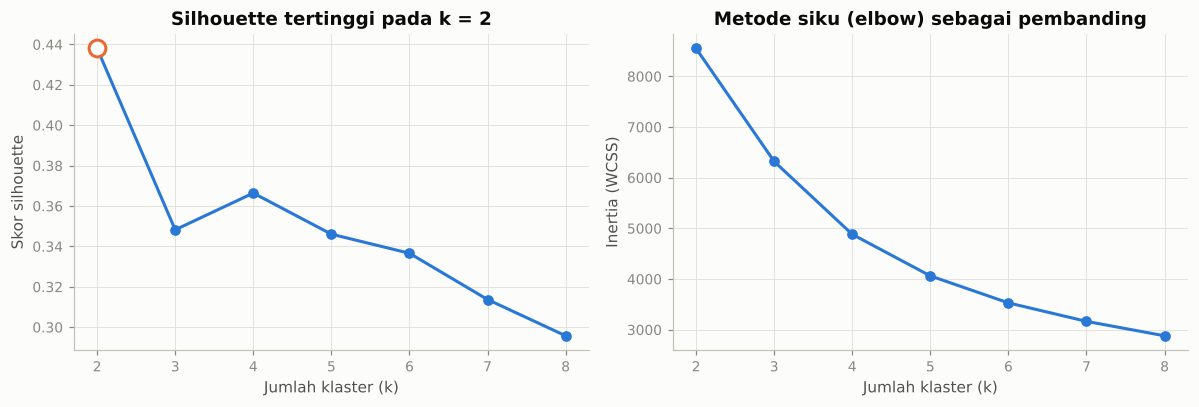

In [5]:
X, scaler = prepare_cluster_features(rfm)
k_scores = select_k_by_silhouette(X, range(2, 9), random_state=42)
display(k_scores.round(4))
best_k = int(k_scores.loc[k_scores["silhouette"].idxmax(), "k"])
print(f"k terbaik menurut silhouette: {best_k}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_scores["k"], k_scores["silhouette"], marker="o", color=SERIES[0])
axes[0].scatter([best_k], [k_scores.loc[k_scores["k"] == best_k, "silhouette"]], s=120, facecolor="white", edgecolor=SERIES[1], linewidth=2, zorder=3)
axes[0].set_xlabel("Jumlah klaster (k)")
axes[0].set_ylabel("Skor silhouette")
axes[0].set_title(f"Silhouette tertinggi pada k = {best_k}")
axes[1].plot(k_scores["k"], k_scores["inertia"], marker="o", color=SERIES[0])
axes[1].set_xlabel("Jumlah klaster (k)")
axes[1].set_ylabel("Inertia (WCSS)")
axes[1].set_title("Metode siku (elbow) sebagai pembanding")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "rfm_silhouette.png")
plt.show()

## 4. Profil klaster KMeans

Setelah k dipilih, setiap klaster diprofilkan: berapa pelanggan, rata-rata R/F/M, dan kontribusi pendapatan. Label bisnis diberikan secara manual berdasarkan profil tersebut (klaster dengan recency rendah + frequency/monetary tinggi = pelanggan inti, dan seterusnya).

In [6]:
rfm_k = rfm.copy()
rfm_k["cluster"] = fit_kmeans(X, best_k, random_state=42)
profile = cluster_profile(rfm_k, "cluster")

# Beri nama bisnis berdasarkan urutan nilai rata-rata monetary (tertinggi = inti).
rank = profile.sort_values("avg_monetary", ascending=False).reset_index(drop=True)
names_by_rank = ["Pelanggan inti (aktif, bernilai tinggi)", "Pelanggan ringan (jarang, lama tidak belanja)", "Klaster 3", "Klaster 4", "Klaster 5", "Klaster 6", "Klaster 7", "Klaster 8"]
label_map = {int(row["cluster"]): names_by_rank[i] for i, row in rank.iterrows()}
rfm_k["cluster_label"] = rfm_k["cluster"].map(label_map)
profile["label"] = profile["cluster"].map(label_map)
display(profile.set_index("label").drop(columns="cluster").sort_values("avg_monetary", ascending=False))

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,share_customers,share_revenue
label,,,,,,,
"Pelanggan inti (aktif, bernilai tinggi)",2335,51.72,12.53,"6,411.29","14,970,361.78",0.40,0.88
"Pelanggan ringan (jarang, lama tidak belanja)",3517,299.67,2.08,596.59,"2,098,206.19",0.60,0.12


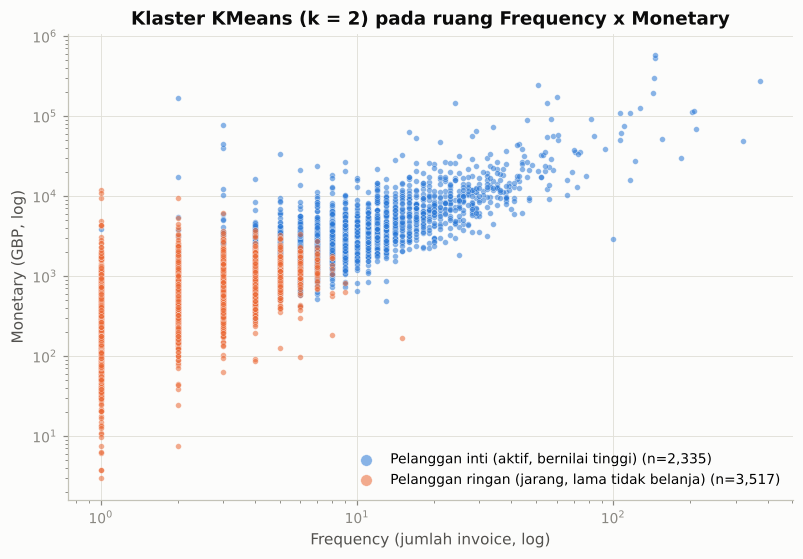

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
labels_sorted = rank["cluster"].map(label_map).tolist()
for i, lab in enumerate(labels_sorted):
    sub = rfm_k[rfm_k["cluster_label"] == lab]
    ax.scatter(sub["frequency"], sub["monetary"].clip(lower=1), s=14, alpha=0.55, color=SERIES[i], edgecolor="white", linewidth=0.3, label=f"{lab} (n={len(sub):,})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Frequency (jumlah invoice, log)")
ax.set_ylabel("Monetary (GBP, log)")
ax.set_title(f"Klaster KMeans (k = {best_k}) pada ruang Frequency x Monetary")
ax.legend(loc="lower right", markerscale=2)
fig.savefig(ASSETS_DIR / "rfm_kmeans.png")
plt.show()

## 5. Perbandingan segmen aturan vs klaster KMeans

Tabel silang menunjukkan seberapa sejalan kedua pendekatan. Idealnya "Champions" dan "Loyal Customers" terkonsentrasi di klaster inti, sedangkan "Lost" dan "Hibernating" di klaster pasif/hilang.

In [8]:
merged = scored.merge(rfm_k[["customer_id", "cluster_label"]], on="customer_id")
crosstab = pd.crosstab(merged["segment"], merged["cluster_label"])
crosstab = crosstab.loc[seg.index, [lab for lab in labels_sorted if lab in crosstab.columns]]
display(crosstab)

# Simpan hasil per pelanggan untuk dipakai dashboard dan dokumentasi.
out = merged[["customer_id", "recency_days", "frequency", "monetary", "r_score", "f_score", "m_score", "rfm_score", "segment", "cluster_label"]]
out.to_csv(REPORTS_DIR / "rfm_segments.csv", index=False)
print(f"Disimpan: {REPORTS_DIR / 'rfm_segments.csv'} ({len(out):,} pelanggan)")

cluster_label,"Pelanggan inti (aktif, bernilai tinggi)","Pelanggan ringan (jarang, lama tidak belanja)"
segment,,
Champions,1304,0
Loyal Customers,702,130
Need Attention,103,354
Potential Loyalists,198,958
Hibernating,0,1178
At Risk,26,42
Lost,0,638
New Customers,2,217


Disimpan: /home/user/portofolio/analisis-penjualan-retail-sql-powerbi/reports/rfm_segments.csv (5,852 pelanggan)


## 6. Alternatif k = 4: lebih halus untuk kebutuhan operasional

Silhouette tertinggi memang pada k = 2, tetapi dua kelompok terlalu kasar untuk merancang kampanye. k = 4 memiliki silhouette tertinggi kedua dan menghasilkan pembagian yang lebih bisa ditindaklanjuti; profilnya ditampilkan sebagai pembanding.

In [9]:
rfm_4 = rfm.copy()
rfm_4["cluster"] = fit_kmeans(X, 4, random_state=42)
profile_4 = cluster_profile(rfm_4, "cluster").sort_values("avg_monetary", ascending=False)
display(profile_4.set_index("cluster"))

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,share_customers,share_revenue
cluster,,,,,,,
2,1191,28.47,19.14,"10,535.34","12,547,595.46",0.20,0.74
0,1447,229.21,5.05,"1,968.07","2,847,791.36",0.25,0.17
1,1260,29.10,3.02,837.80,"1,055,624.89",0.22,0.06
3,1954,395.31,1.38,316.05,"617,556.26",0.33,0.04


## 7. Ringkasan dan rekomendasi tindakan per segmen

**Temuan utama (angka dari eksekusi di atas)**

- Dari 5.852 pelanggan terdaftar, **Champions** hanya 1.304 orang (22,3%) tetapi menyumbang **68,6% pendapatan** (GBP 11,70 juta) dengan rata-rata 16,8 invoice dan belanja GBP 8.976 per pelanggan. Bersama **Loyal Customers** (832 pelanggan, 13,9% pendapatan), sekitar sepertiga basis pelanggan menghasilkan lebih dari 80% pendapatan.
- **Hibernating** (1.178; 20,1%) dan **Lost** (638; 10,9%) sudah tidak berbelanja rata-rata 395-565 hari; mereka adalah 31% basis pelanggan tetapi hanya 4,7% pendapatan.
- **At Risk** kecil (68 pelanggan) namun bernilai tinggi (rata-rata GBP 3.939, 8,1 invoice) dan sudah 495 hari tidak belanja - inilah segmen dengan rasio nilai/upaya penyelamatan terbaik.
- KMeans memilih **k = 2** (silhouette 0,44): klaster *inti* berisi 2.335 pelanggan (40%) yang menyumbang 88% pendapatan, dan klaster *ringan* 3.517 pelanggan (60%) dengan recency rata-rata ~300 hari. Tabel silang menunjukkan seluruh Champions masuk klaster inti dan seluruh Hibernating/Lost masuk klaster ringan, sehingga kedua pendekatan saling mengonfirmasi.

**Rekomendasi tindakan**

| Segmen | Tindakan yang disarankan |
|---|---|
| Champions | Program loyalitas eksklusif, akses awal produk baru, *account manager* untuk pembeli grosir terbesar |
| Loyal Customers | Insentif naik tingkat (diskon volume bertahap), bundel produk pelengkap dari kategori favorit |
| Potential Loyalists / New Customers | Rangkaian email onboarding, rekomendasi produk terlaris di kategori yang pernah dibeli, insentif pembelian kedua |
| Need Attention | Pengingat personal dengan penawaran terbatas waktu sebelum mereka berubah menjadi At Risk |
| At Risk | Kontak langsung oleh tim penjualan (jumlahnya hanya 68) dengan penawaran reaktivasi bernilai tinggi |
| Hibernating / Lost | Kampanye reaktivasi berbiaya rendah (email otomatis); hentikan pengeluaran pemasaran berbayar untuk segmen Lost |

**Catatan metodologis**: hasil segmen dengan SQL (`sql/13_rfm_sql.sql`) sedikit berbeda (mis. Champions 1.355 vs 1.304) karena `NTILE` di SQLite dan `rank(method="first")` di pandas memecah nilai kembar dengan cara berbeda; aturan segmennya identik.